# Exercise 4.3.15

Let $N=50$ and $M \in \{N, 2N, 4N, 6N\}$. For a Gaussian matrix $A \in \mathbb R^{M \times N}$ with $A_{k,j} \sim M^{-1/2} \mathcal N(0,1)$ and the signal $x_* \in \mathbb R^{N}$ 
$$
(x_*)_j = \sin(2 \pi j / N) + 0.5 \sin(6 \pi j / N)  - 0.2 \sin(40 \pi j / N) + 0.3 \sin(10 \pi j / N),
\quad k = 0, \ldots, N-1,
$$ 
compute the associated measurements $y_j = \max\{|(Ax_*)_j|^2 + 0.01\mathcal N(0,1),0\}$. Then, consider the inverse problem $|Ax|^2  = y$.
	
(i) Implement $K$ steps of gradient descent with step size $\nu$ and initial guess $x_0$ for the objective 
$$
f(x) = \frac{1}{2}\sum_{j = 1}^M | \sqrt{|(Ax)_k|^2 + \varepsilon} - \sqrt{y + \varepsilon} |^2
$$
with $\varepsilon = 10^{-4}$.

Your function should return the last iterate $x_K$, the relative measurement errors $\{ f(x_k) / f(0) \}_{k=0}^K$, and the  relative errors $\{ \frac{\min \{ \| x_k - x_* \|_2, \| x_k + x_* \|_2\}}{\| x_*\|_2} \}_{k=0}^K$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(0)

In [2]:
def loss(x,A,y, eps= 1e-4):
    return np.sum( np.abs(np.sqrt(np.abs(A @ x)**2 + eps) - np.sqrt(y + eps))**2)

def pr_gradient_descent(x0, nu, A, y, num_iter, eps = 1e-4, xt = None):
    x = x0
    baseline_loss = loss( np.zeros_like(x0),A,y)
    if xt is not None:
        error = np.zeros((num_iter + 1))
        error[0] = np.min([np.linalg.norm(x-xt), np.linalg.norm(x+xt)]) / np.linalg.norm(xt)

    m_error = np.zeros((num_iter + 1))
    m_error[0] = loss(x0,A,y,eps) / baseline_loss

    for k in range(num_iter):
        forw = A @ x
        grad = A.T @ ((1.0 - np.sqrt(y + eps)/ np.sqrt(np.abs(forw)**2 + eps) ) * forw)
        x = x - nu* grad

        m_error[k+1] = loss(x,A,y,eps) / baseline_loss
        if xt is not None:
            error[k+1] = np.min([np.linalg.norm(x-xt), np.linalg.norm(x+xt)]) / np.linalg.norm(xt)

    if xt is not None:
        return x, m_error, error
    else:
        return x, m_error

(ii) Run your algorithm for $K = 1000$ with initialization $x_0 \sim \mathcal N(0,I_N)$. Plot the reconstructions. What do you observe? Plot the error curves (in $\log_{10}$ scale) and explain your observations.

(iii) Now, change the initialization to $\tilde x_0 = 0.5 x_0 + 0.5 x_*$. Does it improve the performance of the method? Try to justify your observation.

In [3]:
N = 50
idx = np.arange(N)
f = np.sin( 2 * np.pi * idx / N) + 0.5 *np.sin( 6 * np.pi * idx / N) 
f = f - 0.2 * np.sin( 40 * np.pi * idx / N) + 0.3 * np.sin( 10 * np.pi * idx / N)

M_list = [N, 2*N, 4*N, 6*N]
num_iter = 1000


m_errors_all = np.zeros((len(M_list), num_iter + 1))
errors_all = np.zeros((len(M_list), num_iter + 1))
X1 = np.zeros((len(M_list), N))

m_errors_all_x2 = np.zeros((len(M_list), num_iter + 1))
errors_all_x2 = np.zeros((len(M_list), num_iter + 1))
X2 = np.zeros((len(M_list), N))

for im in range(len(M_list)):
    M = M_list[im]
    A = np.random.randn(M,N) / np.sqrt(M)
    y = np.maximum(np.abs(A @ f)**2 + 0.01*np.random.randn(M),0)

    x0 = np.random.randn((N))
    
    nu = 1.0 / np.linalg.norm(A,2)**2

    x1, m_errors, errors = pr_gradient_descent(x0,nu,A,y,num_iter,1e-4,f)
    if np.linalg.norm(x1-f) > np.linalg.norm(x1+f):
        x1 = -x1

    m_errors_all[im,:] = m_errors
    errors_all[im,:] = errors
    X1[im,:] = x1

    x0tilde = 0.5*x0 + 0.5*f
    x2, m_errors, errors = pr_gradient_descent(x0tilde,nu,A,y,num_iter,1e-4,f)
    if np.linalg.norm(x2-f) > np.linalg.norm(x2+f):
        x2 = -x2
        
    m_errors_all_x2[im,:] = m_errors
    errors_all_x2[im,:] = errors
    X2[im,:] = x2

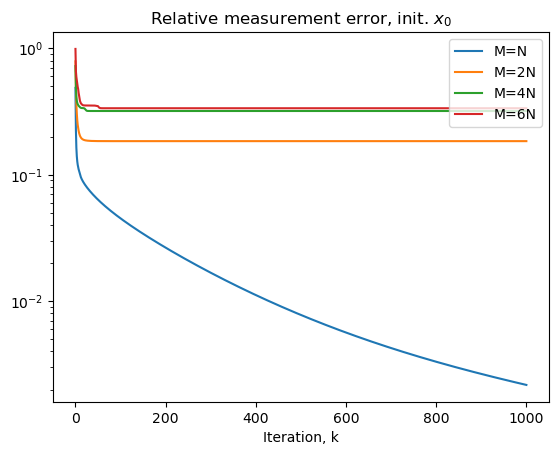

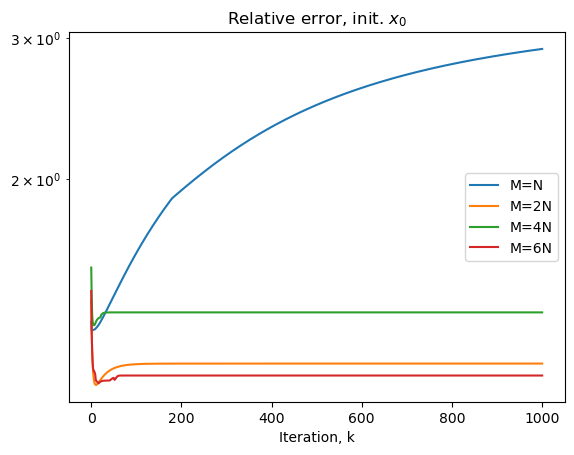

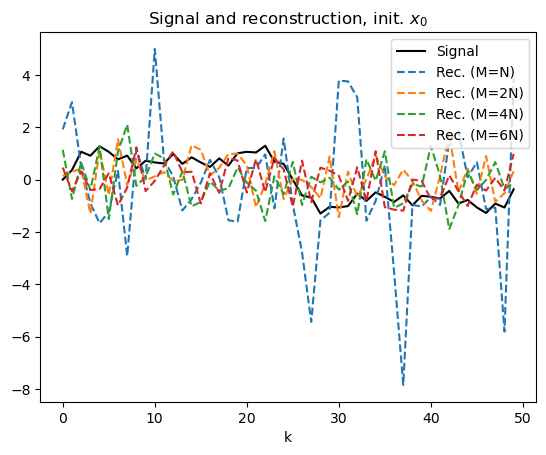

In [4]:
plt.semilogy(m_errors_all.T)
plt.title(r'Relative measurement error, init. $x_0$')
plt.xlabel('Iteration, k')
plt.legend(["M=N", "M=2N", "M=4N", "M=6N"], loc = 'upper right')
plt.show()

plt.semilogy(errors_all.T)
plt.title(r'Relative error, init. $x_0$')
plt.legend(["M=N", "M=2N", "M=4N", "M=6N"], loc = 'center right')
plt.xlabel('Iteration, k')
plt.show()

plt.plot(f,'k')
plt.plot(X1.T, linestyle='dashed')
plt.title(r'Signal and reconstruction, init. $x_0$')
plt.xlabel('k')
plt.legend(["Signal", "Rec. (M=N)", "Rec. (M=2N)", "Rec. (M=4N)", "Rec. (M=6N)"], loc = 'upper right')
plt.show()

Since the loss in phase retrieval is nonconvex, the algorithm stagnates at local minima and does not converge to the global one.
In the case $M = N$, multiple global minima exist, and from the error plots, we observe that the algorithm converges to a wrong one. 

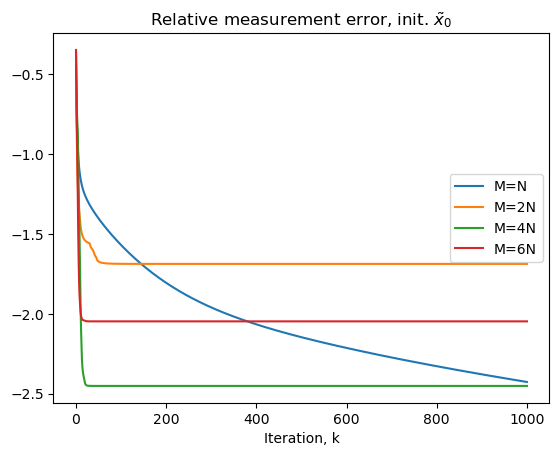

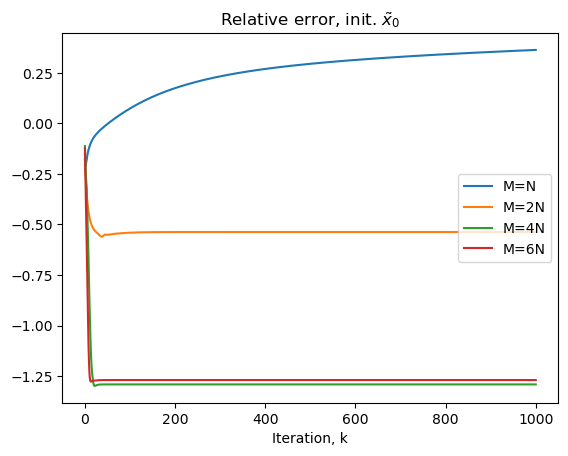

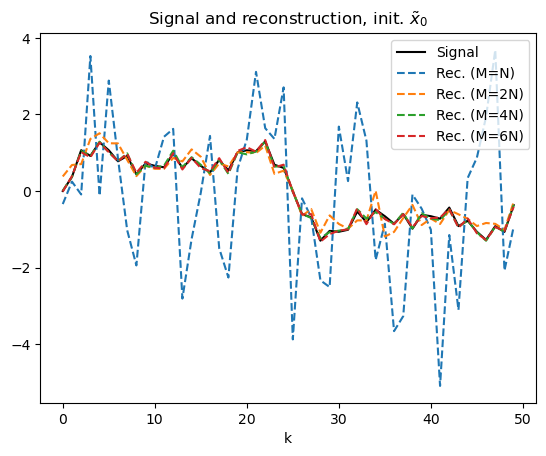

In [5]:
plt.plot(np.log10(m_errors_all_x2.T))
plt.title(r'Relative measurement error, init. $\tilde{x}_0$')
plt.xlabel('Iteration, k')
plt.legend(["M=N", "M=2N", "M=4N", "M=6N"], loc = 'center right')
plt.show()

plt.plot(np.log10(errors_all_x2.T))
plt.title(r'Relative error, init. $\tilde{x}_0$')
plt.legend(["M=N", "M=2N", "M=4N", "M=6N"], loc = 'center right')
plt.xlabel('Iteration, k')
plt.show()

plt.plot(f,'k')
plt.plot(X2.T, linestyle='dashed')
plt.title(r'Signal and reconstruction, init. $\tilde{x}_0$')
plt.xlabel('k')
plt.legend(["Signal", "Rec. (M=N)", "Rec. (M=2N)", "Rec. (M=4N)", "Rec. (M=6N)"], loc = 'upper right')
plt.show()

Improved initialization increases the chance that we are in the neighborhood of a global minimum and within this neighborhood the loss function behaves as a strongly convex function, so that gradient descent converges to a global minimum.